In [ ]:
4.3:Spatial Domain to Frequency Domain

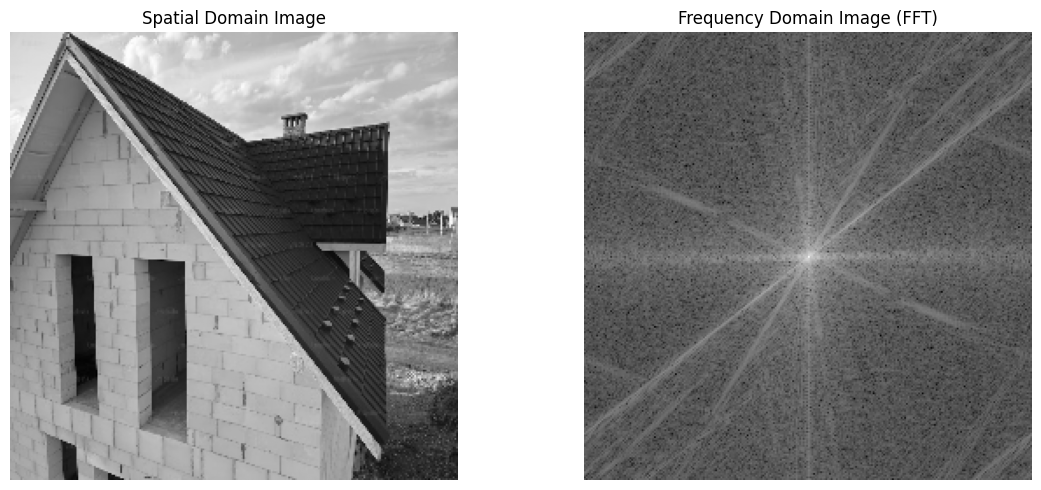

Assignment 4.3 Completed Successfully!
Output saved at: /content/Assignment_4_3_Spatial_to_Frequency.png


In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

# Step 1: Load Image
image_files = (
    glob.glob('/content/*.png') +
    glob.glob('/content/*.jpg') +
    glob.glob('/content/*.jpeg')
)

if not image_files:
    raise FileNotFoundError("Please upload an image to Colab.")

image_path = next(
    (f for f in image_files if os.path.basename(f) == "image.png"),
    image_files[0]
)

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError("Image could not be loaded.")

img = cv2.resize(img, (256, 256))

# Step 2: Apply 2D Fast Fourier Transform
F = np.fft.fft2(img)

# Step 3: Shift the Zero Frequency to the Center
F_shift = np.fft.fftshift(F)

# Step 4: Calculate Magnitude Spectrum
magnitude = np.abs(F_shift)

# Step 5: Apply Log Transformation
magnitude_spectrum = 20 * np.log1p(magnitude)

# Step 6: Display Results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Spatial Domain Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title("Frequency Domain Image (FFT)")
plt.axis('off')

plt.tight_layout()
plt.show()

# Step 7: Save Output
output_path = "/content/Assignment_4_3_Spatial_to_Frequency.png"

cv2.imwrite(
    output_path,
    cv2.normalize(
        magnitude_spectrum,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    ).astype(np.uint8)
)

print("Assignment 4.3 Completed Successfully!")
print("Output saved at:", output_path)